In [19]:
from pathlib import Path
import os
import sys
from tqdm import tqdm as std_tqdm
from functools import partial
tqdm = partial(std_tqdm, dynamic_ncols=True)


PROJECT_DIR = Path.cwd()

sys.path.insert(0, str(PROJECT_DIR))

NESTML_FILE   = PROJECT_DIR / "hh_macica.nestml"
MODULE_TARGET = PROJECT_DIR / "hh_macica_module"

MODULE_NAME   = "hh_macica_module"
NEURON_MODEL  = "hh_macica_nestml"

dyld = os.environ.get("DYLD_LIBRARY_PATH", "")

if str(MODULE_TARGET) not in dyld:
    os.environ["DYLD_LIBRARY_PATH"] = (
        str(MODULE_TARGET) + (":" + dyld if dyld else "")
    )

# ==========================================================
# Imports
# ==========================================================
# ==========================================================
# MACOS COMPILER / SDK FIXES
# MUST RUN BEFORE importing nest or compiling NESTML
# ==========================================================

SDK_PATH = "/Library/Developer/CommandLineTools/SDKs/MacOSX13.sdk"

# ----------------------------------------------------------
# Remove problematic CXXFLAGS
# ----------------------------------------------------------
if "CXXFLAGS" in os.environ:
    del os.environ["CXXFLAGS"]

# ----------------------------------------------------------
# Set SDK paths
# ----------------------------------------------------------
os.environ["SDKROOT"] = SDK_PATH
os.environ["CONDA_BUILD_SYSROOT"] = SDK_PATH

print("SDKROOT =", os.environ.get("SDKROOT"))
print("CONDA_BUILD_SYSROOT =", os.environ.get("CONDA_BUILD_SYSROOT"))
print("CXXFLAGS =", os.environ.get("CXXFLAGS"))

import nest
import numpy as np
import matplotlib.pyplot as plt
from typing import Union 
from scipy.signal import find_peaks

SDKROOT = /Library/Developer/CommandLineTools/SDKs/MacOSX13.sdk
CONDA_BUILD_SYSROOT = /Library/Developer/CommandLineTools/SDKs/MacOSX13.sdk
CXXFLAGS = None


In [20]:
# ==========================================================
# CELL 2 — Compile / install NESTML module
# ==========================================================
def compile_nestml():
    from pynestml.frontend.pynestml_frontend import generate_nest_target
    import inspect

    sig = inspect.signature(generate_nest_target)

    print(f"[NESTML] generate_nest_target signature: {sig}")
    print("[NESTML] Compiling hh_macica.nestml ...")

    kwargs = dict(
        input_path=str(NESTML_FILE),
        target_path=str(MODULE_TARGET),
        module_name=MODULE_NAME,
        logging_level="WARNING",
    )

    accepted = sig.parameters.keys()

    optional = dict(
        suffix="_nestml",
        install_path=str(MODULE_TARGET),
    )

    for k, v in optional.items():
        if k in accepted:
            kwargs[k] = v

    generate_nest_target(**kwargs)

    print("[NESTML] Compilation done.")


def ensure_module_installed():
    try:
        nest.Install(MODULE_NAME)
        print(f"[OK] Installed {MODULE_NAME}")
        return

    except Exception as e:
        err = str(e).lower()

        if "file not found" not in err and "could not be opened" not in err:
            raise

    print("[INFO] Module not found, compiling...")
    compile_nestml()

    try:
        nest.Install(MODULE_NAME)
        print(f"[OK] Installed {MODULE_NAME}")

    except Exception as e:
        raise RuntimeError(
            f"Could not install {MODULE_NAME} after compilation:\n{e}"
        )

# ==========================================================
# CELL 3 — AP analysis function
# ==========================================================
def analyze_ap(t, V):
    peaks, _ = find_peaks(V, height=0, prominence=20)

    if len(peaks) == 0:
        return ["No AP detected"]

    results = []

    for pk in peaks:

        v_peak = V[pk]

        end_idx = min(pk + int(5.0 / DT), len(V) - 1)

        ahp = np.min(V[pk:end_idx]) - V[0]

        v_half = (v_peak + V[0]) / 2.0

        try:
            left  = np.where(V[:pk] < v_half)[0][-1]
            right = np.where(V[pk:] < v_half)[0][0] + pk

            hw = t[right] - t[left]

            results.append({
                "time_ms": round(float(t[pk]), 3),
                "peak_mV": round(float(v_peak), 3),
                "halfwidth_ms": round(float(hw), 3),
                "AHP_mV": round(float(ahp), 3),
            })

        except IndexError:

            results.append({
                "time_ms": round(float(t[pk]), 3),
                "peak_mV": round(float(v_peak), 3),
                "halfwidth_ms": np.nan,
                "AHP_mV": round(float(ahp), 3),
            })

    if len(peaks) > 1:

        isi = np.diff(t[peaks])

        summary = {
            "firing_rate_Hz": round(float(1000.0 / np.mean(isi)), 3),
            "ISI_CV": (
                round(float(np.std(isi) / np.mean(isi)), 3)
                if len(isi) > 1 else np.nan
            ),
            "spike_count": int(len(peaks)),
        }

    else:
        summary = {
            "firing_rate_Hz": np.nan,
            "ISI_CV": np.nan,
            "spike_count": int(len(peaks)),
        }

    return results, summary

def simulate(time: Union[float, int]):
    # split in time chunks
    TIME_PER_CHUNK_TQDM = 1
    chunks = time // TIME_PER_CHUNK_TQDM
    for chunk in tqdm(
        [
            *([TIME_PER_CHUNK_TQDM] * int(chunks)),
            time - int(chunks) * TIME_PER_CHUNK_TQDM,
        ],
        desc="  ⮡ simulation",
    ):
        nest.Simulate(chunk)
        nest.GetStatus(neuron, 'V_m')

In [21]:
nest.ResetKernel()

In [22]:
ensure_module_installed()

[OK] Installed hh_macica_module
May 14 14:43:14 Install [Info]: 

    loaded module hh_macica_module


In [5]:
from params import (
    SIM_DURATION,
    DT,
    REC_VARS,
    PRESETS,
    CP,
)

plt.rcParams["figure.figsize"] = (10, 14)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

preset_name = "MNTB Wild-Type"

params = PRESETS[preset_name].copy()

print(f"Preset: {preset_name}")
print("Parameters:")
for key, value in params.items():
    print(f"  {key}: {value}")

Preset: MNTB Wild-Type
Parameters:
  V_m_init: -63.0
  C_m: 10.0
  E_L: -63
  g_L: 2.0
  refr_T: 1.0
  g_Na: 500.0
  E_Na: 50.0
  k_alpha_m: 76.4
  eta_alpha_m: 0.037
  k_beta_m: 6.93
  eta_beta_m: -0.043
  k_alpha_h: 0.000533
  eta_alpha_h: -0.0909
  k_beta_h: 7.87
  eta_beta_h: 0.0691
  g_Kv3_1: 150.0
  E_Kv3_1: -80.0
  k_alpha_n: 0.2719
  eta_alpha_n: 0.04
  k_beta_n: 0.1974
  eta_beta_n: 0.0
  k_alpha_p: 0.00713
  eta_alpha_p: -0.1942
  k_beta_p: 0.0935
  eta_beta_p: 0.0058
  g_K_LT: 20.0
  E_K_LT: -80.0
  k_alpha_l: 1.2
  eta_alpha_l: 0.03512
  k_beta_l: 0.2248
  eta_beta_l: -0.0319
  k_alpha_r: 0.0438
  eta_alpha_r: -0.0053
  k_beta_r: 0.0562
  eta_beta_r: -0.0047
  I_e: 0.0


In [6]:
nest.SetKernelStatus({
    "resolution": DT,
    "rng_seed": 42,
    "total_num_virtual_procs": 14,
    "local_num_threads": 14
})


May 14 12:51:26 hh_macica_nestml [Warning]: 
    Simulation resolution has changed. Internal state and parameters of the 
    model have been reset!

May 14 12:51:26 SimulationManager::set_status [Info]: 
    Temporal resolution changed from 0.1 to 0.001 ms.


In [7]:
neuron = nest.Create(
    NEURON_MODEL,
    params=params
)

In [8]:
dc_current = 100.0  # pA
dc = nest.Create(
    "dc_generator",
    params={
        "amplitude": dc_current,
        "start": 5.0,
        "stop": 25.0
    }
)

In [9]:
mm = nest.Create(
    "multimeter",
    params={
        "record_from": REC_VARS,
        "interval": DT
    }
)


In [10]:
nest.Connect(dc, neuron)
nest.Connect(mm, neuron)

In [11]:
nest.Simulate(SIM_DURATION)


May 14 12:51:26 NodeManager::prepare_nodes [Info]: 
    Preparing 29 nodes for simulation.

May 14 12:51:26 SimulationManager::start_updating_ [Info]: 
    Number of local nodes: 29
    Simulation time (ms): 50
    Number of OpenMP threads: 14
    Not using MPI

May 14 12:51:26 SimulationManager::run [Info]: 
    Simulation finished.


In [12]:
ev = nest.GetStatus(mm, "events")[0]

t = ev["times"]

V = ev["V_m"]

n = ev["n"]
p = ev["p"]

l = ev["l"]
r = ev["r"]

m = ev["m"]
h = ev["h"]

In [13]:
print(np.min(V), np.max(V))
print("First 20 V values:")
print(V[:20])
print("Last 20 V values:")
print(V[-20:])

-66.70348430893374 22.759972008832786
First 20 V values:
[-63.00032562 -63.00065116 -63.00097662 -63.00130201 -63.00162733
 -63.00195259 -63.00227779 -63.00260293 -63.00292803 -63.00325308
 -63.00357808 -63.00390305 -63.00422797 -63.00455286 -63.00487771
 -63.00520253 -63.00552732 -63.00585207 -63.0061768  -63.0065015 ]
Last 20 V values:
[-64.61341349 -64.61338058 -64.61334767 -64.61331476 -64.61328187
 -64.61324898 -64.6132161  -64.61318323 -64.61315036 -64.6131175
 -64.61308466 -64.61305181 -64.61301898 -64.61298615 -64.61295333
 -64.61292052 -64.61288772 -64.61285492 -64.61282213 -64.61278935]


In [14]:
for var, name in zip([V, n, p, l, r, m, h], ["V_m", "n", "p", "l", "r", "m", "h"]):
    print(f"\n{name}:")
    print(f"  min: {np.min(var)}")
    print(f"  max: {np.max(var)}")
    


V_m:
  min: -66.70348430893374
  max: 22.759972008832786

n:
  min: 0.09413975111815272
  max: 0.30096091353254223

p:
  min: 0.9118235695352374
  max: 0.9999789175103947

l:
  min: 0.05765323138836782
  max: 0.6720791313812042

r:
  min: 0.4443856378068215
  max: 0.4474846889459644

m:
  min: 0.05039493569799537
  max: 0.9854870511911498

h:
  min: 4.4567506537196914e-05
  max: 0.7031641604837638


In [15]:
def _g(k):
    return params[k]


I_Na = (
    _g("g_Na")
    * m**3
    * h
    * (V - _g("E_Na"))
)

I_Kv3_1 = (
    _g("g_Kv3_1")
    * n**3
    * (0.8 + 0.2 * p)
    * (_g("E_Kv3_1") - V)
)

I_K_LT = (
    _g("g_K_LT")
    * l
    * r
    * (_g("E_K_LT") - V)
)

I_L = (
    _g("g_L")
    * (V - _g("E_L"))
)

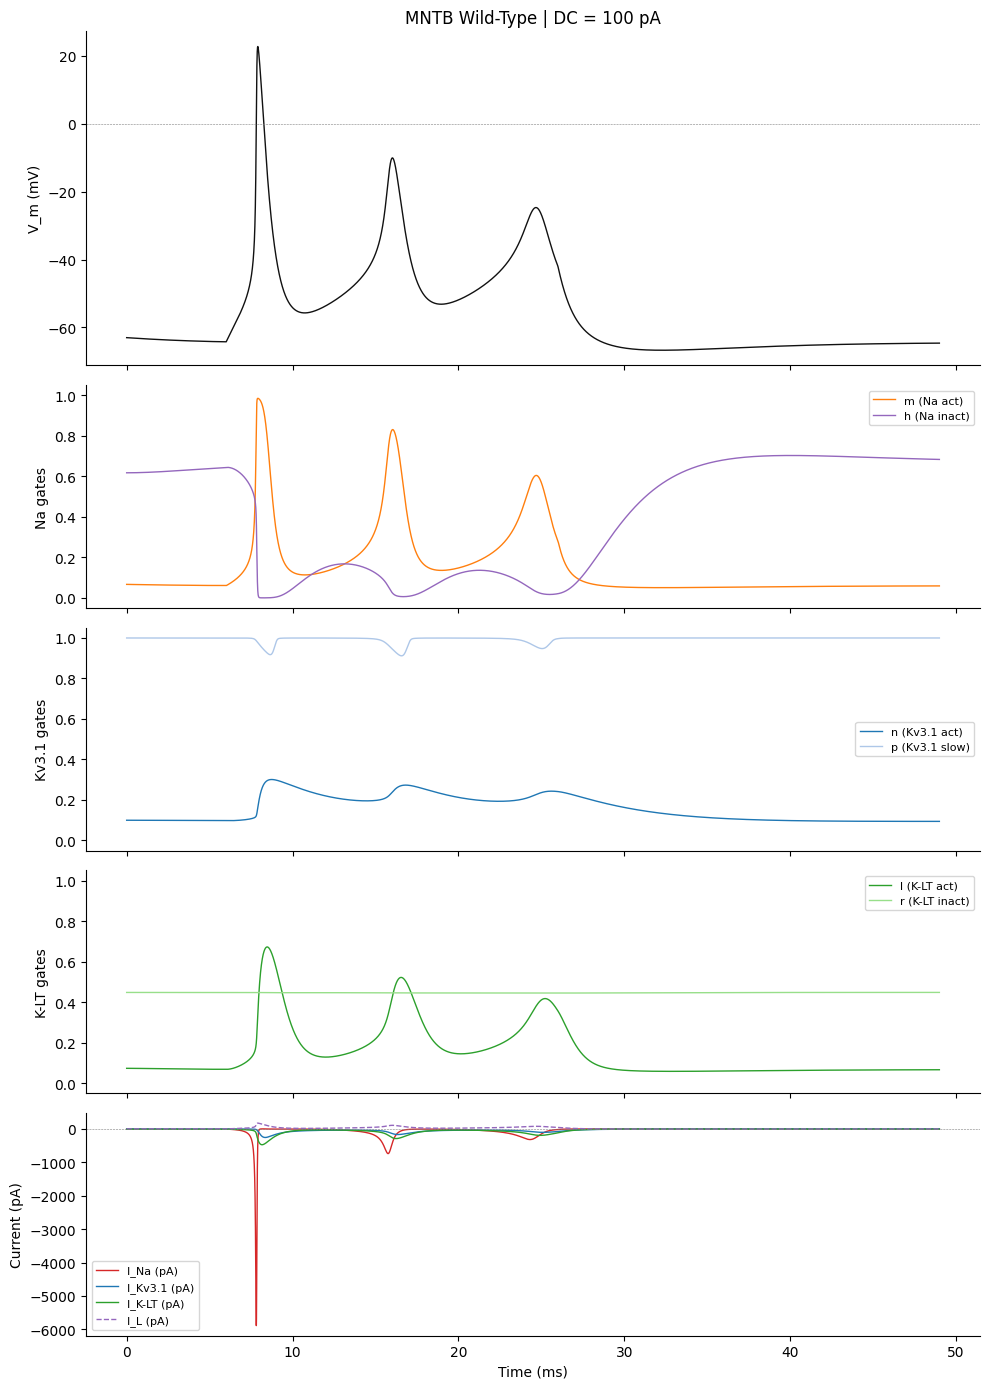

In [16]:
fig, axes = plt.subplots(
    5,
    1,
    figsize=(10, 14),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 2, 2, 2, 2]}
)

ax0, ax1, ax2, ax3, ax4 = axes

# ==========================================================
# V_m
# ==========================================================
ax0.plot(t, V, color=CP["Vm"], lw=1.0)

ax0.set_ylabel("V_m (mV)")

ax0.set_title(
    f"{preset_name} | DC = {dc_current:.0f} pA"
)

ax0.axhline(0, color="gray", lw=0.4, ls="--")

# ==========================================================
# Na gating
# ==========================================================
ax1.plot(
    t,
    m,
    label="m (Na act)",
    color=CP["m"],
    lw=1.0
)

ax1.plot(
    t,
    h,
    label="h (Na inact)",
    color=CP["h"],
    lw=1.0
)

ax1.set_ylabel("Na gates")

ax1.set_ylim(-0.05, 1.05)

ax1.legend(fontsize=8)

# ==========================================================
# Kv3.1 gating
# ==========================================================
ax2.plot(
    t,
    n,
    label="n (Kv3.1 act)",
    color=CP["n"],
    lw=1.0
)

ax2.plot(
    t,
    p,
    label="p (Kv3.1 slow)",
    color=CP["p"],
    lw=1.0
)

ax2.set_ylabel("Kv3.1 gates")

ax2.set_ylim(-0.05, 1.05)

ax2.legend(fontsize=8)

# ==========================================================
# K-LT gating
# ==========================================================
ax3.plot(
    t,
    l,
    label="l (K-LT act)",
    color=CP["l"],
    lw=1.0
)

ax3.plot(
    t,
    r,
    label="r (K-LT inact)",
    color=CP["r"],
    lw=1.0
)

ax3.set_ylabel("K-LT gates")

ax3.set_ylim(-0.05, 1.05)

ax3.legend(fontsize=8)

# ==========================================================
# Ionic currents
# ==========================================================
ax4.plot(
    t,
    I_Na,
    label="I_Na (pA)",
    color=CP["Na"],
    lw=1.0
)

ax4.plot(
    t,
    I_Kv3_1,
    label="I_Kv3.1 (pA)",
    color=CP["Kv3_1"],
    lw=1.0
)

ax4.plot(
    t,
    I_K_LT,
    label="I_K-LT (pA)",
    color=CP["K_LT"],
    lw=1.0
)

ax4.plot(
    t,
    I_L,
    label="I_L (pA)",
    color=CP["h"],
    lw=1.0,
    ls="--"
)

ax4.axhline(
    0,
    color="gray",
    lw=0.4,
    ls="--"
)

ax4.set_ylabel("Current (pA)")
ax4.set_xlabel("Time (ms)")

ax4.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [17]:
results, summary = analyze_ap(t, V)

print("==================================================")
print("Spike analysis")
print("==================================================")

for i, r in enumerate(results):

    print(f"\nSpike {i+1}")

    for k, v in r.items():
        print(f"{k:15s}: {v}")

print("\n==================================================")
print("Summary")
print("==================================================")

for k, v in summary.items():
    print(f"{k:20s}: {v}")

Spike analysis

Spike 1
time_ms        : 7.906
peak_mV        : 22.76
halfwidth_ms   : 0.796
AHP_mV         : 7.286

Summary
firing_rate_Hz      : nan
ISI_CV              : nan
spike_count         : 1


In [18]:
import pandas as pd

df = pd.DataFrame({
    "t_ms": t,
    "V_m": V,
    "m": m,
    "h": h,
    "n": n,
    "p": p,
    "l": l,
    "r": r,
    "I_Na": I_Na,
    "I_Kv3_1": I_Kv3_1,
    "I_K_LT": I_K_LT,
    "I_L": I_L,
})

df.head()

output_file = "hh_macica_results.csv"

df.to_csv(output_file, index=False)

print(f"Saved: {output_file}")

ValueError: Mixing dicts with non-Series may lead to ambiguous ordering.